In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import silhouette_score

Data Collection and Analysis

In [2]:
customer_data = pd.read_csv('../data/Mall_Customers.csv')

In [3]:
customer_data.head(5)

,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


In [4]:
customer_data.shape

(200, 5)

In [5]:
customer_data.info()

<class 'pandas.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype
---  ------                  --------------  -----
 0   CustomerID              200 non-null    int64
 1   Gender                  200 non-null    str  
 2   Age                     200 non-null    int64
 3   Annual Income (k$)      200 non-null    int64
 4   Spending Score (1-100)  200 non-null    int64
dtypes: int64(4), str(1)
memory usage: 8.9 KB


In [6]:
customer_data.isna().sum()

CustomerID                0
Gender                    0
Age                       0
Annual Income (k$)        0
Spending Score (1-100)    0
dtype: int64

Choosing Annual Income & Spending Score Column

In [7]:
features = ['Annual Income (k$)', 'Spending Score (1-100)']

x = customer_data[features]

Feature Scaling

In [8]:
scaler = StandardScaler()

x_scaled = scaler.fit_transform(x)

Chosing the Number of Clusters

In [9]:
wcss = []

for i in range(1, 11):
    kmeans = KMeans(
        n_clusters=i,
        init='k-means++',
        random_state=42,
        n_init=10
    )
    
    kmeans.fit(x_scaled)
    wcss.append(kmeans.inertia_)

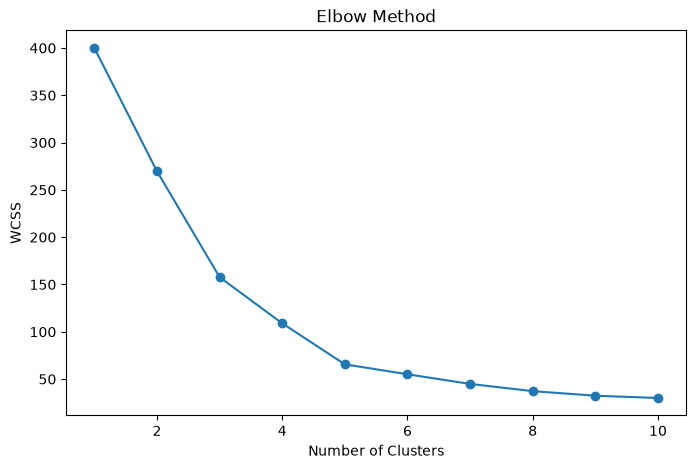

In [10]:
plt.figure(figsize=(8, 5))

plt.plot(range(1, 11), wcss, marker='o')

plt.title('Elbow Method')
plt.xlabel('Number of Clusters')
plt.ylabel('WCSS')

plt.show()

In [11]:
silhouette_scores = {}

for k in range(2, 11):
    kmeans = KMeans(
        n_clusters=k,
        init='k-means++',
        random_state=42,
        n_init=10
    )

    labels = kmeans.fit_predict(x_scaled)

    score = silhouette_score(x_scaled, labels)

    silhouette_scores[k] = score

silhouette_scores

{2: 0.3212707813918878,
 3: 0.46658474419000145,
 4: 0.4939069237513199,
 5: 0.5546571631111091,
 6: 0.5398800926790663,
 7: 0.5281492781108291,
 8: 0.4552147906587443,
 9: 0.4570853966942764,
 10: 0.4431713026508046}

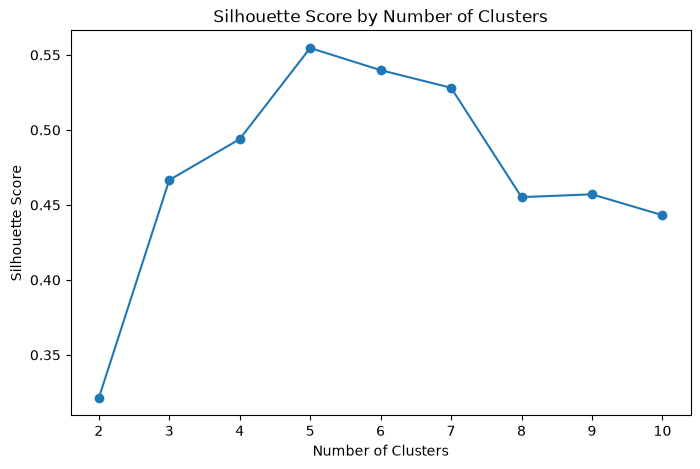

In [12]:
plt.figure(figsize=(8, 5))

plt.plot(
    list(silhouette_scores.keys()),
    list(silhouette_scores.values()),
    marker='o'
)

plt.title('Silhouette Score by Number of Clusters')
plt.xlabel('Number of Clusters')
plt.ylabel('Silhouette Score')

plt.show()

Optimum Number of Clusters = 5

In [13]:
model = Pipeline([
    ('scaler', StandardScaler()),
    ('kmeans', KMeans(
        n_clusters=5,
        init='k-means++',
        random_state=42,
        n_init=10
    ))
])

y = model.fit_predict(x)

print(y)

[4 2 4 2 4 2 4 2 4 2 4 2 4 2 4 2 4 2 4 2 4 2 4 2 4 2 4 2 4 2 4 2 4 2 4 2 4
 2 4 2 4 2 4 0 4 2 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 1 3 1 0 1 3 1 3 1 0 1 3 1 3 1 3 1 3 1 0 1 3 1 3 1
 3 1 3 1 3 1 3 1 3 1 3 1 3 1 3 1 3 1 3 1 3 1 3 1 3 1 3 1 3 1 3 1 3 1 3 1 3
 1 3 1 3 1 3 1 3 1 3 1 3 1 3 1]


Visualizing the Clusters

In [15]:
kmeans = model.named_steps['kmeans']
scaler = model.named_steps['scaler']

cluster_centers = scaler.inverse_transform(
    kmeans.cluster_centers_
)

cluster_centers

array([[55.2962963 , 49.51851852],
       [86.53846154, 82.12820513],
       [25.72727273, 79.36363636],
       [88.2       , 17.11428571],
       [26.30434783, 20.91304348]])

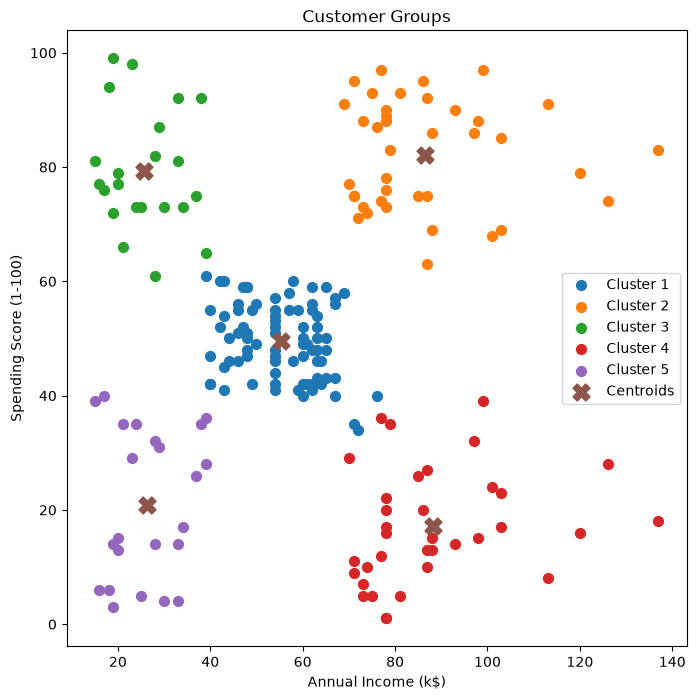

In [16]:
plt.figure(figsize=(8, 8))

plt.scatter(
    x.iloc[y == 0, 0],
    x.iloc[y == 0, 1],
    s=50,
    label='Cluster 1'
)

plt.scatter(
    x.iloc[y == 1, 0],
    x.iloc[y == 1, 1],
    s=50,
    label='Cluster 2'
)

plt.scatter(
    x.iloc[y == 2, 0],
    x.iloc[y == 2, 1],
    s=50,
    label='Cluster 3'
)

plt.scatter(
    x.iloc[y == 3, 0],
    x.iloc[y == 3, 1],
    s=50,
    label='Cluster 4'
)

plt.scatter(
    x.iloc[y == 4, 0],
    x.iloc[y == 4, 1],
    s=50,
    label='Cluster 5'
)

plt.scatter(
    cluster_centers[:, 0],
    cluster_centers[:, 1],
    s=150,
    marker='X',
    label='Centroids'
)

plt.title('Customer Groups')
plt.xlabel('Annual Income (k$)')
plt.ylabel('Spending Score (1-100)')
plt.legend()
plt.show()

In [17]:
customer_data['Cluster'] = y

cluster_profile = customer_data.groupby('Cluster')[features].mean()

cluster_profile

,Annual Income (k$),Spending Score (1-100)
Cluster,,
0,55.296296,49.518519
1,86.538462,82.128205
2,25.727273,79.363636
3,88.200000,17.114286
4,26.304348,20.913043


In [18]:
joblib.dump(model, 'customer_segmentation_model.joblib')

['customer_segmentation_model.joblib']